##**COMPUTER VISION** : **CCA 3**

####Image Restoration & Segmentation, Feature Extraction, Object Recognition, Motion Estimation



| Field | Details |
|---|---|
| **Name** | *Anjali Chavan* |
| **PRN** | *1272251181* |
| **Subject** | *Computer Vision* |


In [1]:
import sys

print("Python Version:", sys.version)
print("Python Environment: Google Colab")
print("Setup Started Successfully!")

Python Version: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
Python Environment: Google Colab
Setup Started Successfully!


In [2]:
!pip install -q ultralytics scikit-image

In [3]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import skimage
import ultralytics

print("OpenCV:", cv2.__version__)
print("NumPy:", np.__version__)
print("Scikit-image:", skimage.__version__)
print("Ultralytics:", ultralytics.__version__)
print("\nAll libraries are ready!")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
OpenCV: 4.14.0
NumPy: 2.1.3
Scikit-image: 0.25.2
Ultralytics: 8.4.194

All libraries are ready!


In [4]:
import os

folders = [
    "dataset/images",
    "dataset/videos",
    "outputs/task1_image_restoration",
    "outputs/task1_segmentation",
    "outputs/task2_feature_extraction",
    "outputs/task3_object_detection",
    "outputs/task4_motion_estimation",
    "report"
]

for folder in folders:
    os.makedirs(folder, exist_ok=True)

print("Project folders created successfully!")

Project folders created successfully!


In [5]:
#Uplaod photo and video

from google.colab import files

uploaded = files.upload()

print("\nUploaded files:")
for filename in uploaded:
    print(filename)

Saving Sample_video.mp4 to Sample_video.mp4
Saving Image_2.jpeg to Image_2.jpeg
Saving Image_1.jpeg to Image_1.jpeg

Uploaded files:
Sample_video.mp4
Image_2.jpeg
Image_1.jpeg


In [6]:
import shutil
import os

image_files = []
video_files = []

for filename in uploaded.keys():
    ext = os.path.splitext(filename)[1].lower()

    if ext in [".jpg", ".jpeg", ".png"]:
        image_files.append(filename)

    elif ext in [".mp4", ".avi", ".mov", ".mkv"]:
        video_files.append(filename)

if len(image_files) < 2:
    raise ValueError("Please upload two photographs.")

if len(video_files) < 1:
    raise ValueError("Please upload one video.")

shutil.copy(image_files[0], "dataset/images/original.jpg")
shutil.copy(image_files[1], "dataset/images/second.jpg")

video_ext = os.path.splitext(video_files[0])[1].lower()

shutil.copy(
    video_files[0],
    "dataset/videos/original_video" + video_ext
)

print("Dataset organized successfully!")

Dataset organized successfully!


###Verifying Dataset

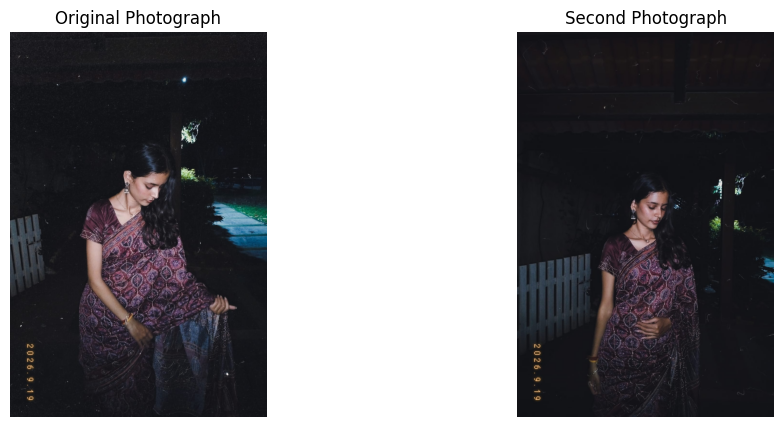

In [9]:
#Verifying Images
import cv2
import matplotlib.pyplot as plt

img1 = cv2.imread("dataset/images/original.jpg")
img2 = cv2.imread("dataset/images/second.jpg")

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(img1, cv2.COLOR_BGR2RGB))
plt.title("Original Photograph")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(img2, cv2.COLOR_BGR2RGB))
plt.title("Second Photograph")
plt.axis("off")

plt.show()

In [8]:
#verifying video

import glob

video_path = glob.glob("dataset/videos/original_video.*")[0]

cap = cv2.VideoCapture(video_path)

print("Video opened:", cap.isOpened())
print("Frame Count:", int(cap.get(cv2.CAP_PROP_FRAME_COUNT)))
print("FPS:", cap.get(cv2.CAP_PROP_FPS))
print("Width:", int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)))
print("Height:", int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT)))

cap.release()

Video opened: True
Frame Count: 300
FPS: 30.0
Width: 368
Height: 368


##**Task 1: Image Restoration and Segmentation**

##**PART A: Image Restoration**

####Import libraries

In [10]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os

from skimage.metrics import peak_signal_noise_ratio
from skimage.metrics import structural_similarity

print("Libraries imported successfully!")

Libraries imported successfully!


####Load the original photograph

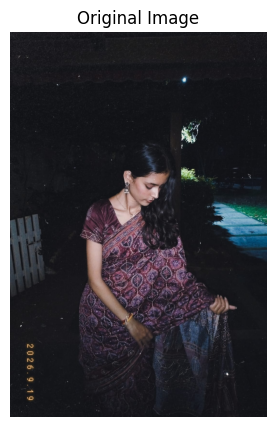

Image dimensions: (1600, 1068, 3)


In [11]:
image_path = "dataset/images/original.jpg"

original = cv2.imread(image_path)

if original is None:
    raise FileNotFoundError("Original image not found!")

original = cv2.cvtColor(original, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(7, 5))
plt.imshow(original)
plt.title("Original Image")
plt.axis("off")
plt.show()

print("Image dimensions:", original.shape)

###**Gaussian Noise**


#####Gaussian noise is random noise that follows a normal distribution. It makes an image look grainy.

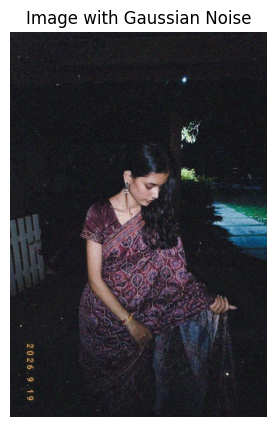

In [12]:
np.random.seed(42)

gaussian_noise = np.random.normal(
    0, 25, original.shape
)

noisy_gaussian = np.clip(
    original.astype(np.float32) + gaussian_noise,
    0, 255
).astype(np.uint8)

plt.figure(figsize=(7, 5))
plt.imshow(noisy_gaussian)
plt.title("Image with Gaussian Noise")
plt.axis("off")
plt.show()

Explanation of parameters:
- 0: Mean of noise.
- 25: Standard deviation controlling noise strength.
- np.clip: Keeps pixel values between 0 and 255.

###**Salt-and-Pepper Noise**

#####Salt-and-Pepper noise introduces random white and black pixels into the image.

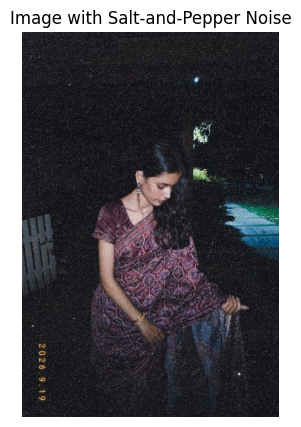

In [13]:
noisy_sp = original.copy()

probability = 0.04
random_map = np.random.random(original.shape[:2])

noisy_sp[random_map < probability/2] = 0
noisy_sp[random_map > 1-probability/2] = 255

plt.figure(figsize=(7, 5))
plt.imshow(noisy_sp)
plt.title("Image with Salt-and-Pepper Noise")
plt.axis("off")
plt.show()

Explanation:
- Black pixels represent pepper noise.
- White pixels represent salt noise.
- 0.04 controls the approximate proportion of affected pixels.

###**Median and Gaussian Filtering**

#####We now restore both noisy images using two filtering techniques.

###**A. Median Filtering**

Median filtering replaces a pixel with the median value of its neighboring pixels. It is especially effective against Salt-and-Pepper noise.

In [14]:
median_gaussian = cv2.medianBlur(noisy_gaussian, 5)
median_sp = cv2.medianBlur(noisy_sp, 5)

###**B. Gaussian Filtering**

Gaussian filtering smooths an image using a weighted average of neighboring pixels. It is useful for reducing Gaussian noise.

In [15]:
gaussian_gaussian = cv2.GaussianBlur(
    noisy_gaussian, (5, 5), 0
)

gaussian_sp = cv2.GaussianBlur(
    noisy_sp, (5, 5), 0
)

###**Restoration Results**

####Compare the Original, Noisy and Restored Images together.

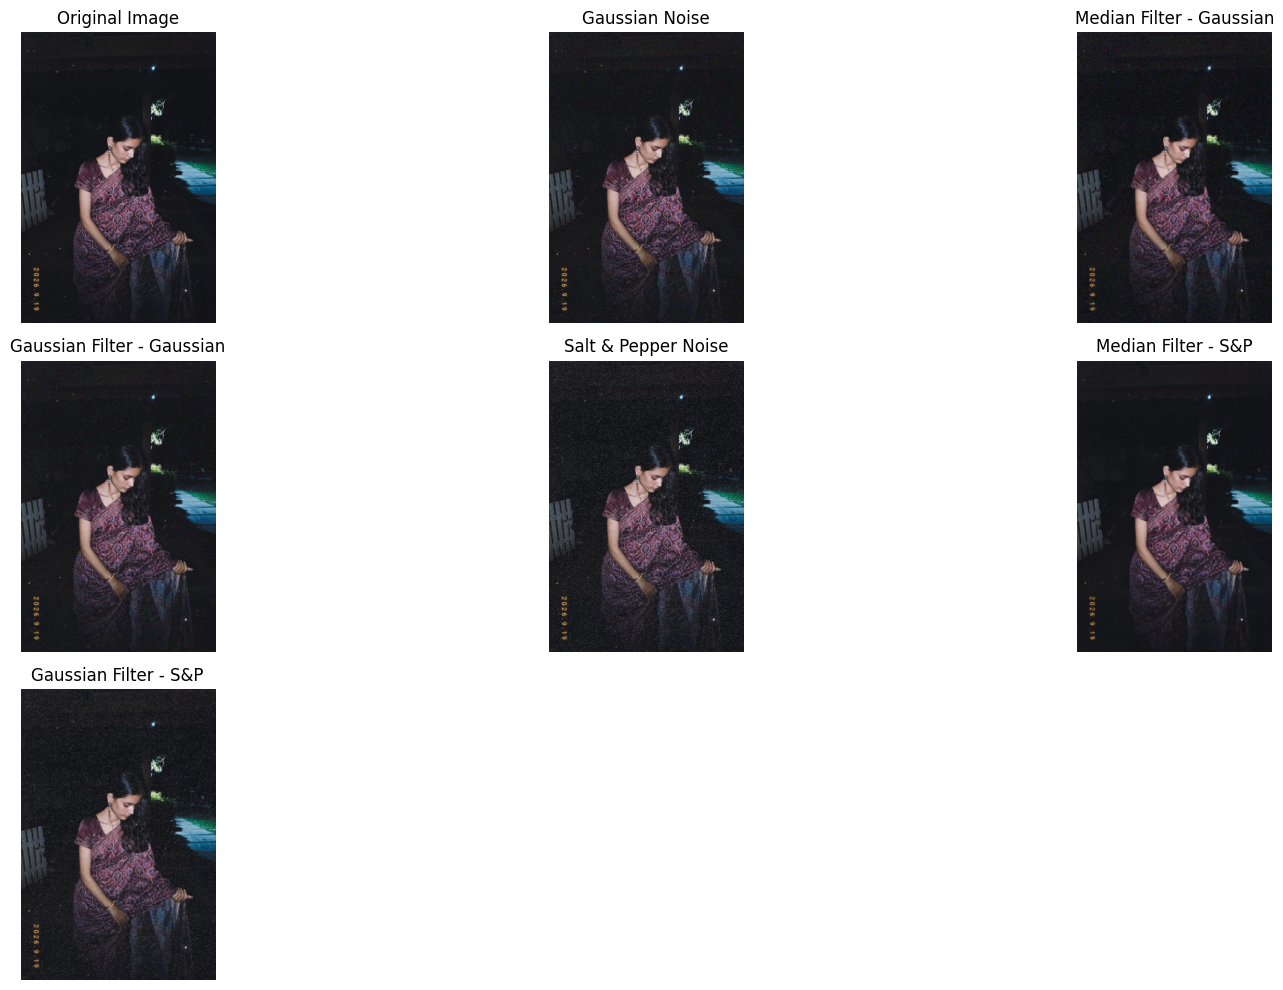

In [16]:
images = [
    original,
    noisy_gaussian,
    median_gaussian,
    gaussian_gaussian,
    noisy_sp,
    median_sp,
    gaussian_sp
]

titles = [
    "Original Image",
    "Gaussian Noise",
    "Median Filter - Gaussian",
    "Gaussian Filter - Gaussian",
    "Salt & Pepper Noise",
    "Median Filter - S&P",
    "Gaussian Filter - S&P"
]

plt.figure(figsize=(16, 10))

for i in range(len(images)):
    plt.subplot(3, 3, i+1)
    plt.imshow(images[i])
    plt.title(titles[i])
    plt.axis("off")

plt.tight_layout()
plt.show()

What to observe:
- Gaussian noise makes the image grainy.
- Salt-and-Pepper noise produces black and white dots.
- Median filtering should perform particularly well on Salt-and-Pepper noise.
- Gaussian filtering should reduce Gaussian noise, although it may blur some details.

###**Calculate PSNR and SSIM**

###**1. PSNR – Peak Signal-to-Noise Ratio**

####PSNR measures the difference between the original and restored images.
#####- Higher PSNR = better restoration.
#####- It is measured in decibels (dB).

###**2. SSIM – Structural Similarity Index**

####SSIM measures similarity in image structure, brightness and contrast.
#####- Closer to 1 = more similar to the original.
#####- Closer to 0 = less similar.

In [17]:
def calculate_metrics(reference, restored):

    psnr = peak_signal_noise_ratio(
        reference, restored, data_range=255
    )

    ssim = structural_similarity(
        reference,
        restored,
        channel_axis=-1,
        data_range=255
    )

    return round(psnr, 2), round(ssim, 4)


results = {
    "Gaussian + Median": median_gaussian,
    "Gaussian + Gaussian Filter": gaussian_gaussian,
    "S&P + Median": median_sp,
    "S&P + Gaussian Filter": gaussian_sp
}

print("RESTORATION PERFORMANCE\n")

for name, result in results.items():

    p, s = calculate_metrics(original, result)

    print(name)
    print("PSNR:", p, "dB")
    print("SSIM:", s)
    print("----------------------")

RESTORATION PERFORMANCE

Gaussian + Median
PSNR: 27.05 dB
SSIM: 0.6543
----------------------
Gaussian + Gaussian Filter
PSNR: 28.65 dB
SSIM: 0.6977
----------------------
S&P + Median
PSNR: 28.59 dB
SSIM: 0.8949
----------------------
S&P + Gaussian Filter
PSNR: 26.69 dB
SSIM: 0.6124
----------------------


In [18]:
#Save restoration outputs
save_path = "outputs/task1_image_restoration"

os.makedirs(save_path, exist_ok=True)

output_images = {
    "original.png": original,
    "gaussian_noise.png": noisy_gaussian,
    "salt_pepper_noise.png": noisy_sp,
    "median_gaussian.png": median_gaussian,
    "gaussian_filter_gaussian.png": gaussian_gaussian,
    "median_salt_pepper.png": median_sp,
    "gaussian_filter_salt_pepper.png": gaussian_sp
}

for filename, image in output_images.items():

    cv2.imwrite(
        os.path.join(save_path, filename),
        cv2.cvtColor(image, cv2.COLOR_RGB2BGR)
    )

print("Restoration outputs saved successfully!")

Restoration outputs saved successfully!


##**Part B – Morphological Processing and Segmentation**

###**Convert image to grayscale**

####Grayscale conversion removes color information and represents the image using intensity values.

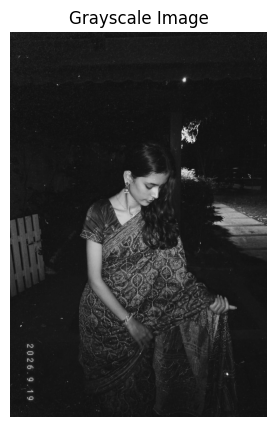

In [19]:
gray = cv2.cvtColor(original, cv2.COLOR_RGB2GRAY)

plt.figure(figsize=(7, 5))
plt.imshow(gray, cmap="gray")
plt.title("Grayscale Image")
plt.axis("off")
plt.show()

###**Binary Thresholding**

####Thresholding converts a grayscale image into a binary image containing black and white pixels.

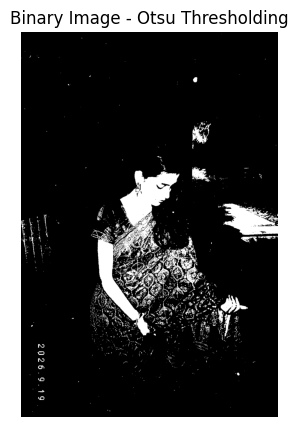

Calculated Threshold: 79.0


In [20]:
threshold_value, binary = cv2.threshold(
    gray,
    0,
    255,
    cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

plt.figure(figsize=(7, 5))
plt.imshow(binary, cmap="gray")
plt.title("Binary Image - Otsu Thresholding")
plt.axis("off")
plt.show()

print("Calculated Threshold:", threshold_value)

###**Morphological Operations**

####Morphological operations modify the shape and structure of objects in a binary image

####We will perform four operations:
| Operation | Purpose |
|------|----------|
| Erosion | Shrinks white regions |
| Dilation | 	Expands white regions |
| Opening | Removes small white noise |
| Closing | 	Fills small black holes |




In [21]:
kernel = np.ones((5, 5), np.uint8)

####**A. Erosion**

In [22]:
erosion = cv2.erode(binary, kernel, iterations=1)

####**B. Dilation**

In [23]:
dilation = cv2.dilate(binary, kernel, iterations=1)

####**C. Opening**

In [24]:
opening = cv2.morphologyEx(
    binary, cv2.MORPH_OPEN, kernel
)

####**D. Closing**

In [25]:
closing = cv2.morphologyEx(
    binary, cv2.MORPH_CLOSE, kernel
)

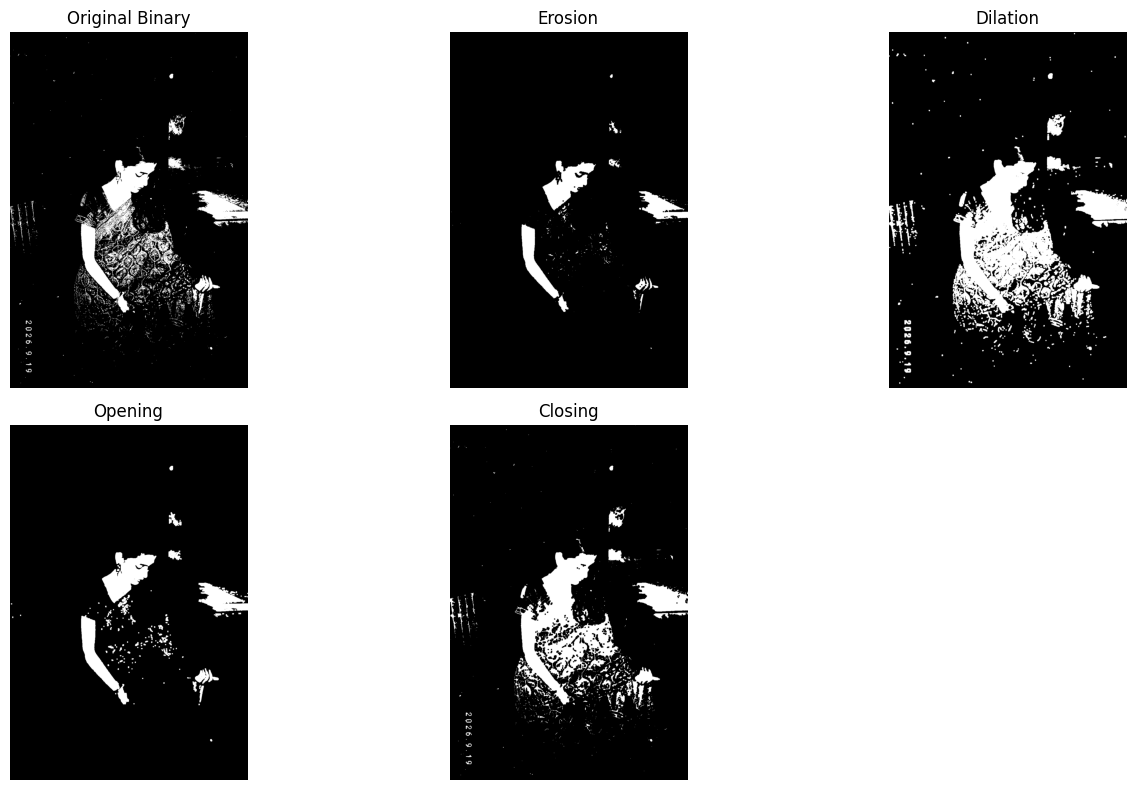

In [26]:
#Display all four results:
morph_images = [
    binary,
    erosion,
    dilation,
    opening,
    closing
]

morph_titles = [
    "Original Binary",
    "Erosion",
    "Dilation",
    "Opening",
    "Closing"
]

plt.figure(figsize=(14, 8))

for i in range(5):
    plt.subplot(2, 3, i+1)
    plt.imshow(morph_images[i], cmap="gray")
    plt.title(morph_titles[i])
    plt.axis("off")

plt.tight_layout()
plt.show()

###**Canny Edge Detection**

####Canny edge detection identifies boundaries and changes in intensity within an image.It helps identify the outlines of objects.

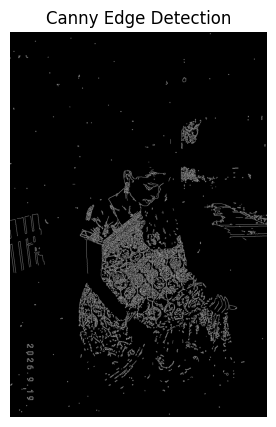

In [27]:
edges = cv2.Canny(gray, 100, 200)

plt.figure(figsize=(7, 5))
plt.imshow(edges, cmap="gray")
plt.title("Canny Edge Detection")
plt.axis("off")
plt.show()

The parameters:
- 100: Lower threshold.
- 200: Upper threshold.

###**Watershed Segmentation**

####Watershed is a segmentation technique used to separate touching or overlapping objects.

####It treats an image like a geographical surface and identifies boundaries between regions.

For this experiment, we'll use:
- Binary thresholding.
- Morphological opening.
- Distance transform.
- Connected component labeling.
- Watershed algorithm.

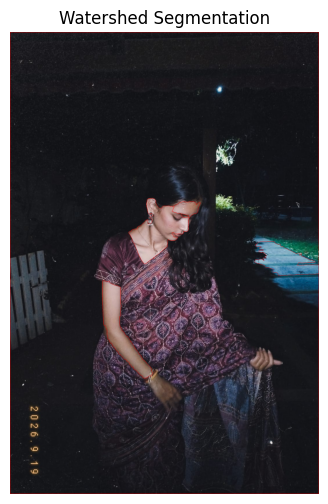

Number of foreground labels: 4


In [28]:
# Remove noise
opening_ws = cv2.morphologyEx(
    binary,
    cv2.MORPH_OPEN,
    np.ones((3, 3), np.uint8),
    iterations=2
)

# Identify sure background
sure_bg = cv2.dilate(
    opening_ws,
    np.ones((3, 3), np.uint8),
    iterations=3
)

# Distance transform
dist_transform = cv2.distanceTransform(
    opening_ws, cv2.DIST_L2, 5
)

# Identify sure foreground
_, sure_fg = cv2.threshold(
    dist_transform,
    0.4 * dist_transform.max(),
    255,
    0
)

sure_fg = np.uint8(sure_fg)

# Identify unknown regions
unknown = cv2.subtract(sure_bg, sure_fg)

# Connected component labeling
num_labels, markers = cv2.connectedComponents(sure_fg)

# Prepare markers
markers = markers + 1
markers[unknown == 255] = 0

# Apply watershed
watershed_image = cv2.cvtColor(
    original, cv2.COLOR_RGB2BGR
)

markers = cv2.watershed(
    watershed_image, markers
)

# Visualize boundaries
watershed_result = original.copy()
watershed_result[markers == -1] = [255, 0, 0]

plt.figure(figsize=(8, 6))
plt.imshow(watershed_result)
plt.title("Watershed Segmentation")
plt.axis("off")
plt.show()

print("Number of foreground labels:", num_labels - 1)

In [29]:
#Save all segmentation outputs
save_path = "outputs/task1_segmentation"

os.makedirs(save_path, exist_ok=True)

segmentation_images = {
    "grayscale.png": gray,
    "binary_threshold.png": binary,
    "erosion.png": erosion,
    "dilation.png": dilation,
    "opening.png": opening,
    "closing.png": closing,
    "canny_edges.png": edges,
    "watershed.png": watershed_result,
    "sure_foreground.png": sure_fg,
    "sure_background.png": sure_bg
}

for filename, image in segmentation_images.items():

    if len(image.shape) == 3:
        image = cv2.cvtColor(
            image, cv2.COLOR_RGB2BGR
        )

    cv2.imwrite(
        os.path.join(save_path, filename),
        image
    )

print("All segmentation outputs saved successfully!")

All segmentation outputs saved successfully!


####**Final Task 1 comparison**

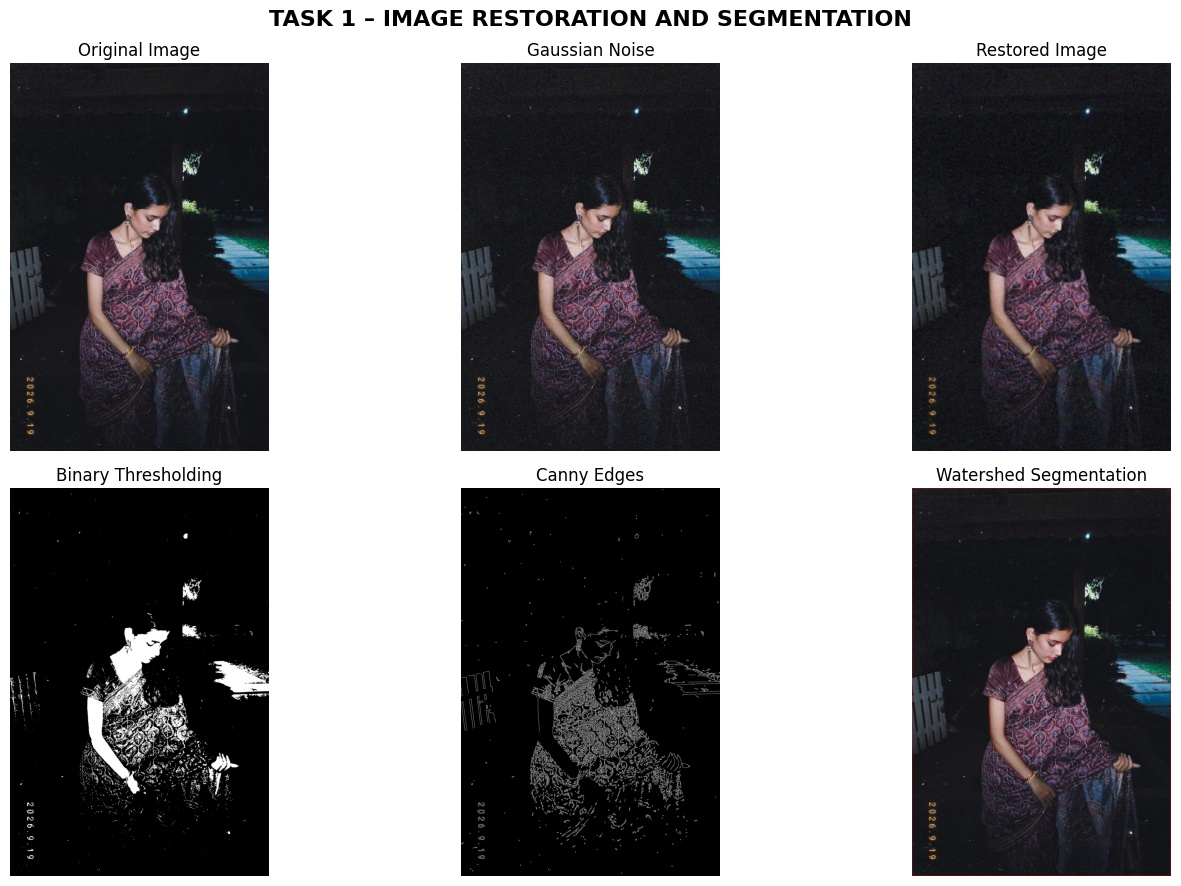

In [30]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))

comparison = [
    (original, "Original Image", None),
    (noisy_gaussian, "Gaussian Noise", None),
    (median_gaussian, "Restored Image", None),
    (binary, "Binary Thresholding", "gray"),
    (edges, "Canny Edges", "gray"),
    (watershed_result, "Watershed Segmentation", None)
]

for ax, (img, title, cmap) in zip(axes.flat, comparison):
    ax.imshow(img, cmap=cmap)
    ax.set_title(title, fontsize=12)
    ax.axis("off")

plt.suptitle(
    "TASK 1 – IMAGE RESTORATION AND SEGMENTATION",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    "outputs/task1_image_restoration/task1_summary.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

In [31]:
#Download your Task 1 outputs
import shutil

shutil.make_archive(
    "Task1_Outputs",
    "zip",
    "outputs"
)

from google.colab import files

files.download("Task1_Outputs.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

##**Task 2: Feature Extraction and Image Matching (Unit 4).**

####Load and prepare both photographs

Image 1: (1600, 1068, 3)
Image 2: (1600, 1068, 3)
Both images loaded successfully!


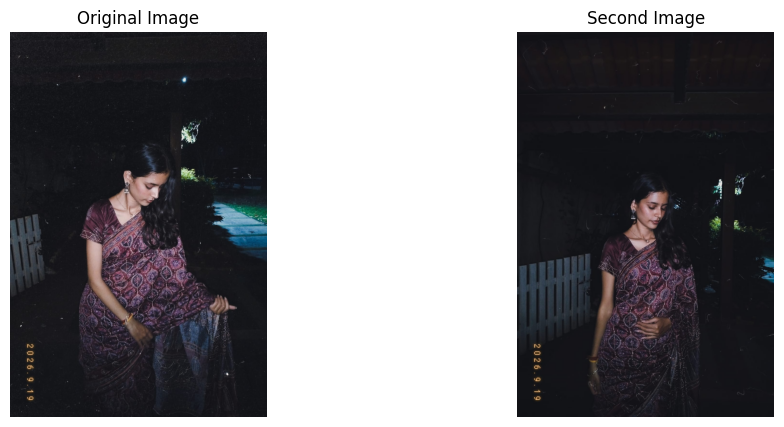

In [35]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

from skimage.feature import hog
from skimage import exposure

# Load photographs
img1 = cv2.imread("dataset/images/original.jpg")
img2 = cv2.imread("dataset/images/second.jpg")

# Convert BGR to RGB for display
img1_rgb = cv2.cvtColor(img1, cv2.COLOR_BGR2RGB)
img2_rgb = cv2.cvtColor(img2, cv2.COLOR_BGR2RGB)

# Convert to grayscale
gray1 = cv2.cvtColor(img1, cv2.COLOR_BGR2GRAY)
gray2 = cv2.cvtColor(img2, cv2.COLOR_BGR2GRAY)

print("Image 1:", img1.shape)
print("Image 2:", img2.shape)
print("Both images loaded successfully!")

# Display images
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(img1_rgb)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(img2_rgb)
plt.title("Second Image")
plt.axis("off")

plt.show()

###**HOG feature extraction**

####HOG identifies the shape and structure of objects by analysing the direction and strength of image gradients.

Image 1 HOG feature length: 945648
Image 2 HOG feature length: 945648


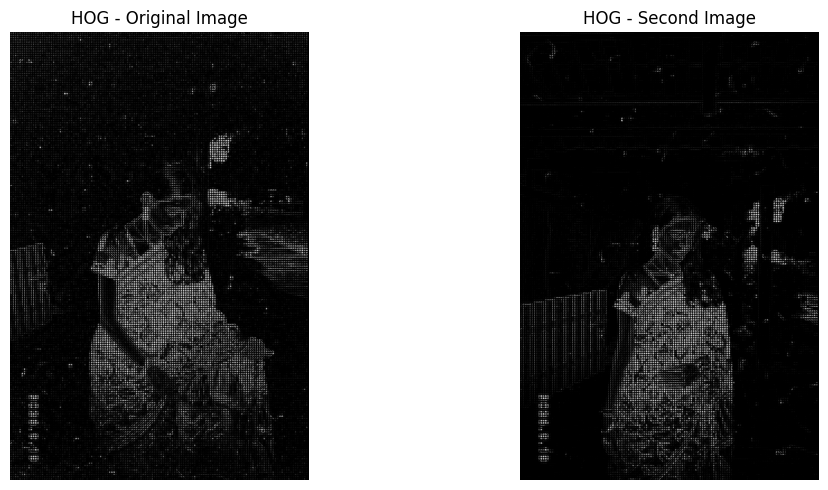

In [36]:
# Extract HOG features
features1, hog_image1 = hog(
    gray1,
    orientations=9,
    pixels_per_cell=(8, 8),
    cells_per_block=(2, 2),
    visualize=True
)

features2, hog_image2 = hog(
    gray2,
    orientations=9,
    pixels_per_cell=(8, 8),
    cells_per_block=(2, 2),
    visualize=True
)

# Improve HOG visualisation
hog_image1 = exposure.rescale_intensity(
    hog_image1, in_range=(0, 10)
)

hog_image2 = exposure.rescale_intensity(
    hog_image2, in_range=(0, 10)
)

print("Image 1 HOG feature length:", len(features1))
print("Image 2 HOG feature length:", len(features2))

# Display HOG visualisations
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(hog_image1, cmap="gray")
plt.title("HOG - Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(hog_image2, cmap="gray")
plt.title("HOG - Second Image")
plt.axis("off")

plt.tight_layout()
plt.show()

###**SIFT keypoint detection**

####SIFT (Scale-Invariant Feature Transform) detects distinctive points in an image, such as corners, edges and textured regions. It generates descriptors that help identify matching points between photographs.

Image 1 keypoints: 4051
Image 2 keypoints: 2263


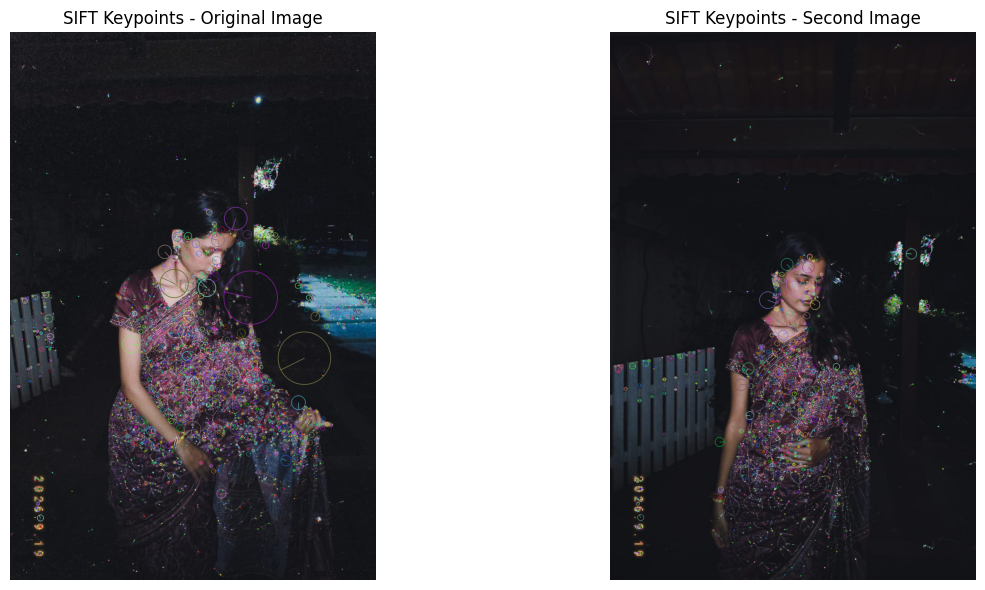

In [37]:
# Create SIFT detector
sift = cv2.SIFT_create()

# Detect keypoints and descriptors
kp1, des1 = sift.detectAndCompute(gray1, None)
kp2, des2 = sift.detectAndCompute(gray2, None)

print("Image 1 keypoints:", len(kp1))
print("Image 2 keypoints:", len(kp2))

# Draw keypoints
sift_img1 = cv2.drawKeypoints(
    img1_rgb, kp1, None,
    flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS
)

sift_img2 = cv2.drawKeypoints(
    img2_rgb, kp2, None,
    flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS
)

# Display results
plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
plt.imshow(sift_img1)
plt.title("SIFT Keypoints - Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(sift_img2)
plt.title("SIFT Keypoints - Second Image")
plt.axis("off")

plt.tight_layout()
plt.show()

####Results:
| Measurements | First image | Second image |
|------|----------|--------------------  |
| HOG feature length | 945,648	 | 945,648 |
| SIFT keypoints | 	4,051 | 2,263 |

**Observation:** The original photograph contains more detected SIFT keypoints than the second photograph. This indicates that SIFT identified more distinctive local features in the original image. It does not necessarily mean that the image is better.

###**SIFT feature matching**

Now we'll match the keypoints between both photographs using:
- BFMatcher: Finds descriptor pairs with similar features.
- Lowe's Ratio Test: Filters out less reliable matches.

Total matches: 4051
Good matches: 186


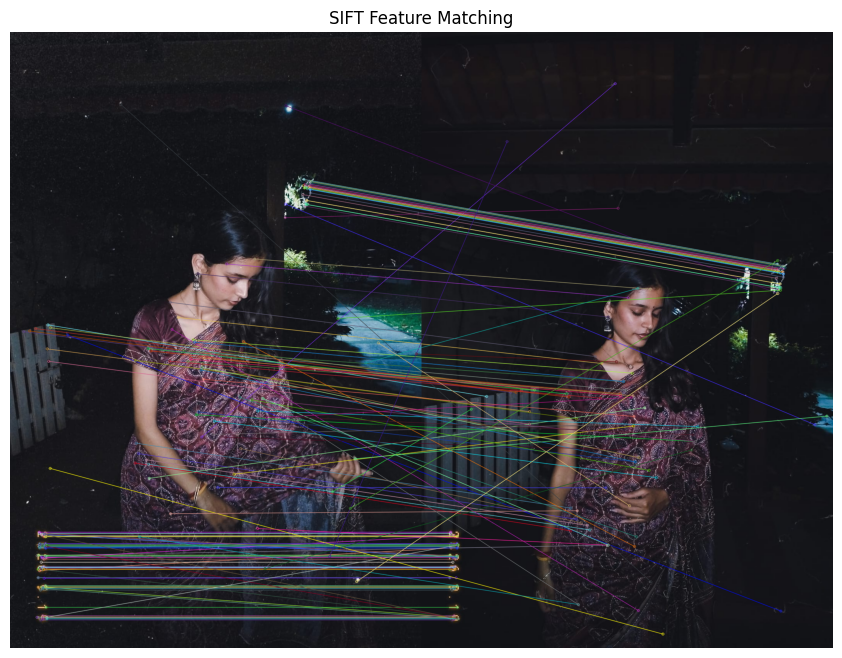

In [38]:
# Create Brute Force Matcher
bf = cv2.BFMatcher()

# Find two nearest matches
matches = bf.knnMatch(des1, des2, k=2)

# Apply Lowe's Ratio Test
good_matches = []

for m, n in matches:
    if m.distance < 0.75 * n.distance:
        good_matches.append(m)

print("Total matches:", len(matches))
print("Good matches:", len(good_matches))

# Draw matching features
match_img = cv2.drawMatches(
    img1_rgb, kp1,
    img2_rgb, kp2,
    good_matches, None,
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)

plt.figure(figsize=(16, 8))
plt.imshow(match_img)
plt.title("SIFT Feature Matching")
plt.axis("off")
plt.show()

####Results:
| Measurements | Result |
|------|----------|
| Total descriptor matches | 4,051	 |
| Good matches after ratio test | 	186 |
| Ratio threshold | 	0.75 |

**Observation:** Out of 4,051 candidate matches, 186 passed Lowe's Ratio Test. The ratio test removes ambiguous matches and retains more distinctive feature correspondences.

###**Test matching after rotation and resizing**

Now we'll check whether SIFT can still identify matching features when the second photograph is transformed.

We'll perform two experiments:
1. Rotate the second image by 45°.
2. Resize the second image to 50%.

SIFT Matching - 45 Degree Rotation | Good matches: 150


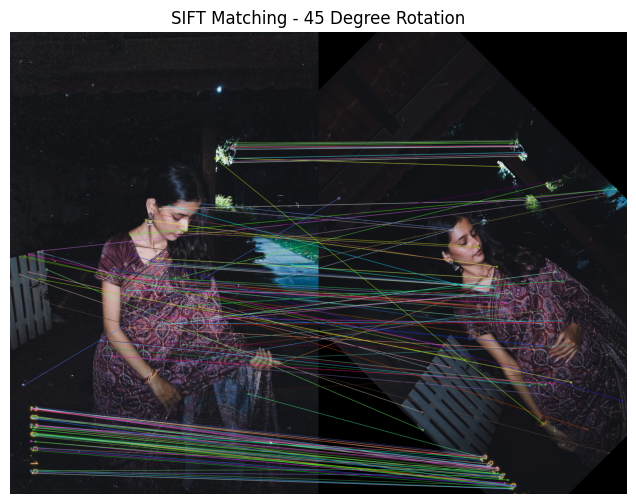

SIFT Matching - 50% Resizing | Good matches: 101


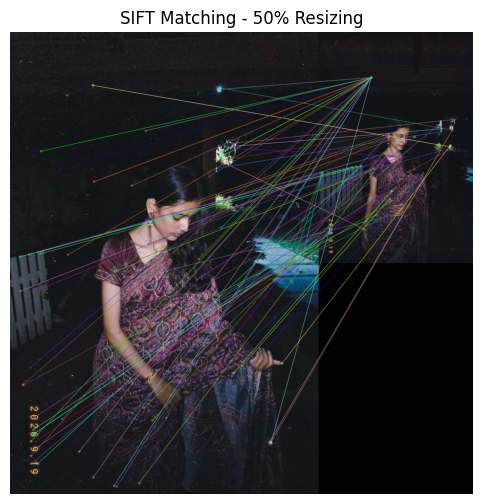

In [39]:
# Function to perform SIFT matching
def match_sift(image1, image2, title):

    gray_a = cv2.cvtColor(image1, cv2.COLOR_BGR2GRAY)
    gray_b = cv2.cvtColor(image2, cv2.COLOR_BGR2GRAY)

    kp_a, des_a = sift.detectAndCompute(gray_a, None)
    kp_b, des_b = sift.detectAndCompute(gray_b, None)

    matches = bf.knnMatch(des_a, des_b, k=2)

    good = [
        m for m, n in matches
        if m.distance < 0.75 * n.distance
    ]

    result = cv2.drawMatches(
        image1, kp_a,
        image2, kp_b,
        good, None,
        flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
    )

    print(title, "| Good matches:", len(good))

    plt.figure(figsize=(15, 6))
    plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
    plt.title(title)
    plt.axis("off")
    plt.show()


# Experiment 1: Rotate second image by 45 degrees
h, w = img2.shape[:2]

matrix = cv2.getRotationMatrix2D(
    (w // 2, h // 2), 45, 1
)

rotated = cv2.warpAffine(
    img2, matrix, (w, h)
)

match_sift(img1, rotated, "SIFT Matching - 45 Degree Rotation")


# Experiment 2: Resize second image to 50%
resized = cv2.resize(
    img2, None, fx=0.5, fy=0.5
)

match_sift(img1, resized, "SIFT Matching - 50% Resizing")

####Results:
| Experiments | Good matches |
|------|----------|
| Original vs. second image | 186	 |
| Second image rotated by 45° | 	150 |
| Second image resized to 50% | 	101 |

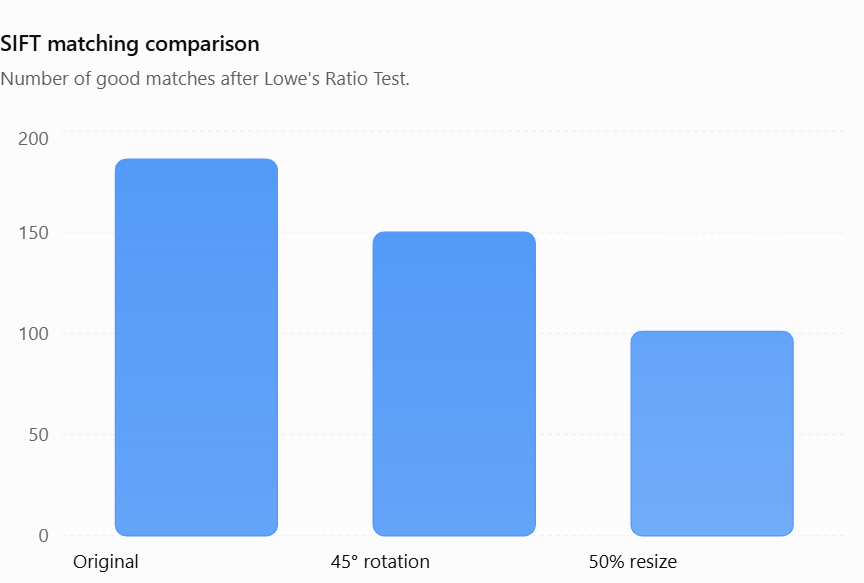

**Observations:**
1. The original image pair produced the highest number of good matches (186).
2. After rotating the second image by 45°, the good matches decreased to 150.
3. After resizing the second image to 50%, the good matches decreased to 101.
4. SIFT successfully detected matching features even after rotation and resizing.
5. The results demonstrate some degree of rotation and scale invariance, although transformations can reduce the number of reliable matches.

In [40]:
#Save Task 2 output images
import os
import cv2
import matplotlib.pyplot as plt

output_folder = "outputs/task2_feature_extraction"
os.makedirs(output_folder, exist_ok=True)

# Save HOG visualisations
plt.imsave(
    f"{output_folder}/hog_original.png",
    hog_image1, cmap="gray"
)

plt.imsave(
    f"{output_folder}/hog_second.png",
    hog_image2, cmap="gray"
)

# Save SIFT keypoint images
cv2.imwrite(
    f"{output_folder}/sift_original.png",
    cv2.cvtColor(sift_img1, cv2.COLOR_RGB2BGR)
)

cv2.imwrite(
    f"{output_folder}/sift_second.png",
    cv2.cvtColor(sift_img2, cv2.COLOR_RGB2BGR)
)

print("Task 2 output images saved successfully!")

Task 2 output images saved successfully!


##**Task 3 – Object Recognition Using Viola–Jones and YOLO (Unit 5).**

In [41]:
!pip install -q ultralytics

Image loaded: (1600, 1068, 3)


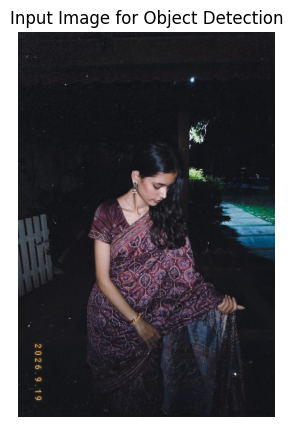

In [42]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os

from ultralytics import YOLO

# Load original photograph
img = cv2.imread("dataset/images/original.jpg")
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

print("Image loaded:", img.shape)

# Create output folder
output_folder = "outputs/task3_object_detection"
os.makedirs(output_folder, exist_ok=True)

# Display image
plt.figure(figsize=(8, 5))
plt.imshow(img_rgb)
plt.title("Input Image for Object Detection")
plt.axis("off")
plt.show()

###**Viola–Jones face detection**

We'll use OpenCV's pretrained Haar Cascade face detector.

Faces detected using Viola-Jones: 1


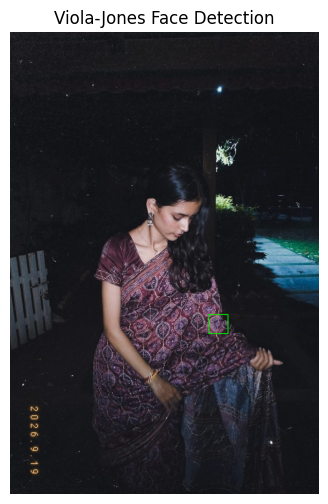

In [43]:
# Load Haar Cascade classifier
face_cascade = cv2.CascadeClassifier(
    cv2.data.haarcascades +
    "haarcascade_frontalface_default.xml"
)

# Convert image to grayscale
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Detect faces
faces = face_cascade.detectMultiScale(
    gray,
    scaleFactor=1.1,
    minNeighbors=5,
    minSize=(30, 30)
)

# Draw bounding boxes
viola_img = img_rgb.copy()

for (x, y, w, h) in faces:
    cv2.rectangle(
        viola_img,
        (x, y),
        (x + w, y + h),
        (0, 255, 0),
        2
    )

print("Faces detected using Viola-Jones:", len(faces))

# Display result
plt.figure(figsize=(9, 6))
plt.imshow(viola_img)
plt.title("Viola-Jones Face Detection")
plt.axis("off")
plt.show()

**Report observation:** Viola–Jones successfully detected one frontal face in the input photograph using Haar-like features and a cascade classifier.

###**YOLO object detection**

Now we'll use YOLOv8 Nano (yolov8n.pt), a lightweight pretrained object detection model.

Unlike Viola–Jones, YOLO can detect multiple object categories, such as people, cars, chairs, bottles and more.


0: 640x448 1 person, 378.2ms
Speed: 9.2ms preprocess, 378.2ms inference, 32.8ms postprocess per image at shape (1, 3, 640, 448)
YOLO Detection Results:
Object: person | Confidence: 0.894


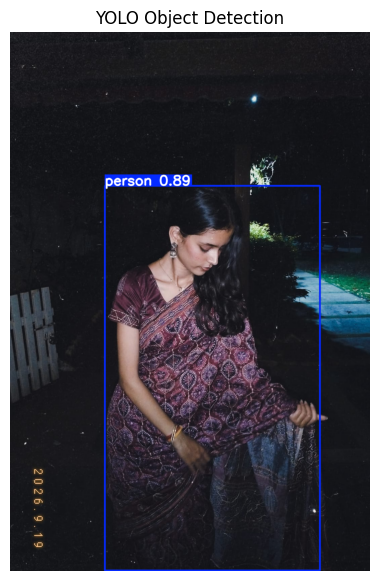

In [44]:
# Load pretrained YOLOv8 Nano model
model = YOLO("yolov8n.pt")

# Perform object detection
results = model(img, conf=0.25)

# Display detected objects
yolo_img = results[0].plot()

# Print detection details
print("YOLO Detection Results:")

for box in results[0].boxes:
    class_id = int(box.cls[0])
    confidence = float(box.conf[0])

    print(
        "Object:", model.names[class_id],
        "| Confidence:", round(confidence, 3)
    )

# Display output
plt.figure(figsize=(10, 7))
plt.imshow(cv2.cvtColor(yolo_img, cv2.COLOR_BGR2RGB))
plt.title("YOLO Object Detection")
plt.axis("off")
plt.show()

**Report observation:** YOLO successfully detected one person with a confidence score of 89.4%. The model identifies the object and provides a bounding box and confidence score.

**Compare Viola–Jones and YOLO**
**Results:**
| Feature |	Viola–Jones	| YOLO |
|------|--------------|-----------------|
| Method |	Haar Cascade |	Deep learning |
| Detection |	Face | Multiple object categories |
|Result |	1 face |	1 person |
| Confidence score	| Not provided	| 89.4% |
| Output |Bounding box |	Label, bounding box and confidence |

In [45]:
#save the task
# Save Viola-Jones output
cv2.imwrite(
    "outputs/task3_object_detection/viola_jones.png",
    cv2.cvtColor(viola_img, cv2.COLOR_RGB2BGR)
)

# Save YOLO output
cv2.imwrite(
    "outputs/task3_object_detection/yolo_detection.png",
    yolo_img
)

print("Task 3 output images saved successfully!")

Task 3 output images saved successfully!


###**Test YOLO on your video**


0: 640x640 1 sports ball, 128.3ms
Speed: 2.7ms preprocess, 128.3ms inference, 0.6ms postprocess per image at shape (1, 3, 640, 640)
YOLO detection on video frame:
sports ball | Confidence: 0.293


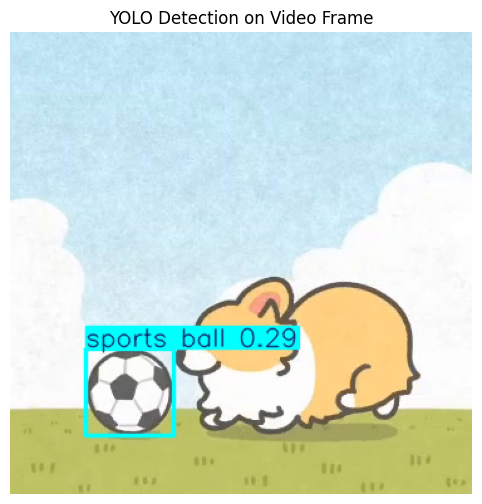

In [46]:
video_path = "dataset/videos/original_video.mp4"

cap = cv2.VideoCapture(video_path)

# Read one frame from the middle of the video
total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
cap.set(cv2.CAP_PROP_POS_FRAMES, total_frames // 2)

ret, frame = cap.read()
cap.release()

if ret:
    video_result = model(frame, conf=0.25)
    video_output = video_result[0].plot()

    print("YOLO detection on video frame:")

    for box in video_result[0].boxes:
        class_id = int(box.cls[0])
        confidence = float(box.conf[0])

        print(
            model.names[class_id],
            "| Confidence:",
            round(confidence, 3)
        )

    plt.figure(figsize=(10, 6))
    plt.imshow(cv2.cvtColor(video_output, cv2.COLOR_BGR2RGB))
    plt.title("YOLO Detection on Video Frame")
    plt.axis("off")
    plt.show()

    cv2.imwrite(
        "outputs/task3_object_detection/yolo_video_frame.png",
        video_output
    )
else:
    print("Unable to read video frame.")

####Result:
| Measurement | Result |
|--------------|----------|
|Object detected	| Sports ball |
| Number of detections |	1 |
| Confidence score |	0.293 (29.3%) |
| Model	| YOLOv8 Nano |

**Report observation**: YOLO detected one sports ball in the selected middle frame of the video, with a confidence score of 29.3%. This is a relatively low-confidence detection, so it should be interpreted cautiously.

**The photograph and video produced different detections:**
- Photograph: Person — 89.4% confidence.
- Video frame: Sports ball — 29.3% confidence.

In [47]:
#save task 3
import os

output_folder = "outputs/task3_object_detection"

print("TASK 3 SAVED FILES:")

for file in os.listdir(output_folder):
    print("✔", file)

TASK 3 SAVED FILES:
✔ viola_jones.png
✔ yolo_video_frame.png
✔ yolo_detection.png


##**Task 4 – Motion Estimation (Unit 5)**

In [48]:
#Load and inspect the video
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os

# Video path
video_path = "dataset/videos/original_video.mp4"

# Create output folder
output_folder = "outputs/task4_motion_estimation"
os.makedirs(output_folder, exist_ok=True)

# Open video
cap = cv2.VideoCapture(video_path)

if not cap.isOpened():
    print("Error: Unable to open video")
else:
    fps = cap.get(cv2.CAP_PROP_FPS)
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

    print("Video loaded successfully!")
    print("FPS:", fps)
    print("Total frames:", total_frames)
    print("Duration:", round(total_frames / fps, 2), "seconds")

cap.release()

Video loaded successfully!
FPS: 30.0
Total frames: 300
Duration: 10.0 seconds


###**Frame Differencing**

####Frame differencing detects movement by subtracting one video frame from the next. Areas with significant changes are highlighted as moving regions.

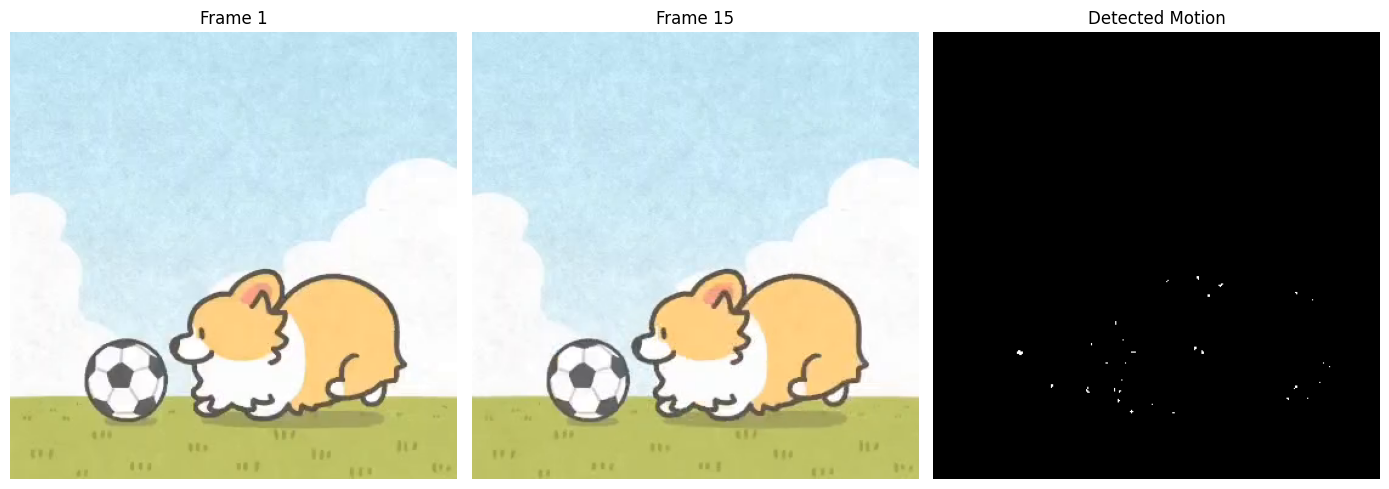

Frame differencing completed!


In [50]:
cap = cv2.VideoCapture(video_path)

# Read frame 1
cap.set(cv2.CAP_PROP_POS_FRAMES, 0)
ret1, frame1 = cap.read()

# Read frame 15
cap.set(cv2.CAP_PROP_POS_FRAMES, 15)
ret2, frame2 = cap.read()

cap.release()

if ret1 and ret2:

    gray1 = cv2.cvtColor(frame1, cv2.COLOR_BGR2GRAY)
    gray2 = cv2.cvtColor(frame2, cv2.COLOR_BGR2GRAY)

    # Calculate difference
    difference = cv2.absdiff(gray1, gray2)

    # Reduce noise
    difference = cv2.GaussianBlur(difference, (5, 5), 0)

    # Apply threshold
    _, threshold = cv2.threshold(
        difference, 15, 255, cv2.THRESH_BINARY
    )

    # Display results
    plt.figure(figsize=(14, 5))

    plt.subplot(1, 3, 1)
    plt.imshow(cv2.cvtColor(frame1, cv2.COLOR_BGR2RGB))
    plt.title("Frame 1")
    plt.axis("off")

    plt.subplot(1, 3, 2)
    plt.imshow(cv2.cvtColor(frame2, cv2.COLOR_BGR2RGB))
    plt.title("Frame 15")
    plt.axis("off")

    plt.subplot(1, 3, 3)
    plt.imshow(threshold, cmap="gray")
    plt.title("Detected Motion")
    plt.axis("off")

    plt.tight_layout()
    plt.show()

    cv2.imwrite(
        f"{output_folder}/frame_difference.png",
        threshold
    )

    print("Frame differencing completed!")

else:
    print("Unable to read video frames.")

**Observation:** Comparing frames 1 and 15 revealed small motion regions around the ball and other moving image elements. The method detects changes between frames, although minor movements produce relatively sparse results.

###**Background Subtraction using MOG2**

####MOG2 (Mixture of Gaussians) models the background over time and identifies moving objects as foreground.

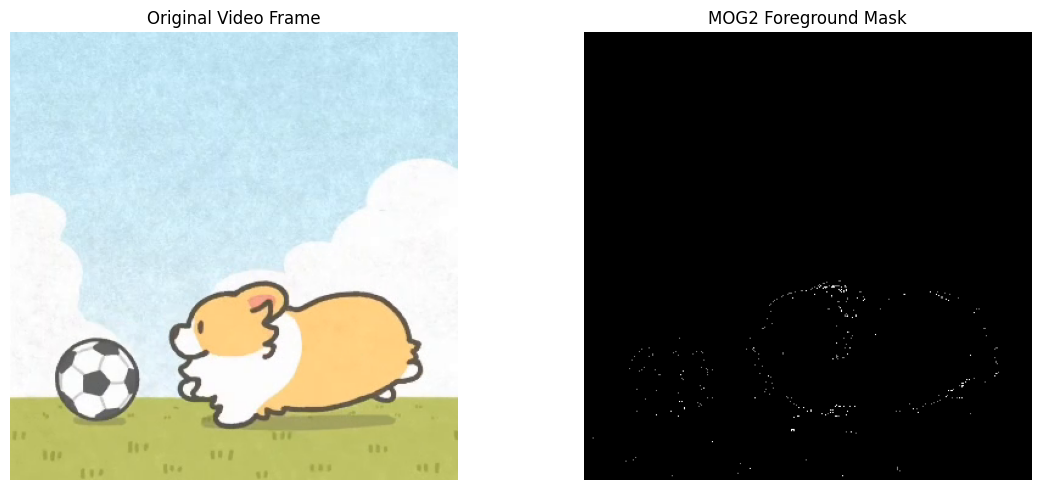

MOG2 background subtraction completed!
Frames processed: 300


In [51]:
# Open video
cap = cv2.VideoCapture(video_path)

# Create MOG2 background subtractor
back_sub = cv2.createBackgroundSubtractorMOG2(
    history=100,
    varThreshold=25,
    detectShadows=True
)

frame_count = 0
foreground = None
original_frame = None

while True:
    ret, frame = cap.read()

    if not ret:
        break

    foreground = back_sub.apply(frame)
    original_frame = frame
    frame_count += 1

cap.release()

# Display final frame and foreground mask
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(original_frame, cv2.COLOR_BGR2RGB))
plt.title("Original Video Frame")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(foreground, cmap="gray")
plt.title("MOG2 Foreground Mask")
plt.axis("off")

plt.tight_layout()
plt.show()

# Save output
cv2.imwrite(
    f"{output_folder}/mog2_foreground.png",
    foreground
)

print("MOG2 background subtraction completed!")
print("Frames processed:", frame_count)

**Report observation**
MOG2 models the background over successive frames and generates a foreground mask to identify changes. Its output depends on the background model, movement and shadow detection settings.

###**Lucas–Kanade Optical Flow**

####Lucas–Kanade Optical Flow tracks selected feature points between consecutive frames and estimates the direction and movement of those points.

####We'll use Shi–Tomasi corner detection to select points and Lucas–Kanade to track them.

Detected feature points: 42
Successfully tracked points: 42


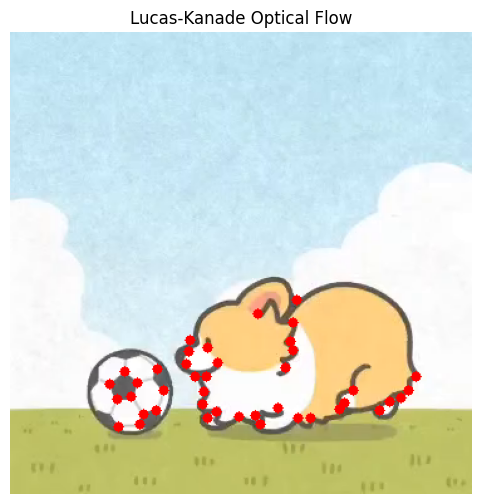

In [52]:
# Open video
cap = cv2.VideoCapture(video_path)

# Read first frame
ret, old_frame = cap.read()

if ret:

    old_gray = cv2.cvtColor(old_frame, cv2.COLOR_BGR2GRAY)

    # Detect feature points
    corners = cv2.goodFeaturesToTrack(
        old_gray,
        maxCorners=100,
        qualityLevel=0.3,
        minDistance=7,
        blockSize=7
    )

    # Lucas-Kanade parameters
    lk_params = dict(
        winSize=(15, 15),
        maxLevel=2,
        criteria=(
            cv2.TERM_CRITERIA_EPS |
            cv2.TERM_CRITERIA_COUNT,
            10, 0.03
        )
    )

    # Read next frame
    ret, frame = cap.read()

    if ret and corners is not None:

        frame_gray = cv2.cvtColor(
            frame, cv2.COLOR_BGR2GRAY
        )

        # Track feature points
        new_points, status, error = cv2.calcOpticalFlowPyrLK(
            old_gray,
            frame_gray,
            corners,
            None,
            **lk_params
        )

        # Draw tracked points and motion lines
        output = frame.copy()

        good_new = new_points[status == 1]
        good_old = corners[status == 1]

        for new, old in zip(good_new, good_old):

            x1, y1 = new.ravel().astype(int)
            x2, y2 = old.ravel().astype(int)

            cv2.line(
                output, (x1, y1), (x2, y2),
                (0, 255, 0), 2
            )

            cv2.circle(
                output, (x1, y1),
                4, (0, 0, 255), -1
            )

        print("Detected feature points:", len(corners))
        print("Successfully tracked points:", len(good_new))

        # Display result
        plt.figure(figsize=(10, 6))
        plt.imshow(cv2.cvtColor(output, cv2.COLOR_BGR2RGB))
        plt.title("Lucas-Kanade Optical Flow")
        plt.axis("off")
        plt.show()

        # Save output
        cv2.imwrite(
            f"{output_folder}/lucas_kanade.png",
            output
        )

    else:
        print("Unable to track feature points.")

else:
    print("Unable to read video.")

cap.release()

####Result:
| Measurement |	Result |
|------------------|----------|
| Feature points detected |	42 |
| Successfully tracked points |	42 |
| Tracking success |	100% |

**Report observation:** Lucas–Kanade Optical Flow successfully tracked all 42 selected feature points between consecutive video frames. The algorithm estimated their movement using changes in feature positions.

In [53]:
#verify all task 4 outputs
import os

output_folder = "outputs/task4_motion_estimation"

print("TASK 4 OUTPUT FILES")
print("-------------------")

for file in sorted(os.listdir(output_folder)):
    path = os.path.join(output_folder, file)

    if os.path.isfile(path):
        print("✓", file)

print("\nTask 4 processing completed!")

TASK 4 OUTPUT FILES
-------------------
✓ frame_difference.png
✓ lucas_kanade.png
✓ mog2_foreground.png

Task 4 processing completed!


####**Task 4 Comparison Table**

| Technique |	Purpose	| result |
|----------------|--------------------|---------------|
| Frame Differencing |	Detect changes between frames |	Motion regions detected |
| MOG2 |	Separate foreground from background	 | 300 frames processed |
| Lucas–Kanade |	Track feature-point movement	 |42/42 points tracked |

**Overall Task 4 conclusion**

The three motion estimation techniques were successfully implemented on the recorded video. Frame differencing identified changes between selected frames, MOG2 processed all 300 frames for foreground extraction, and Lucas–Kanade successfully tracked 42 feature points. These experiments demonstrate different approaches to identifying and estimating motion in video sequences.